(reliability_index_example)=
# Reliability index $\beta$
In section {ref}`structural_safety` we have seen the definition of the reliability factor $\beta$, using a symbolic approach. Now, we will show some examples with values as well as python-implementation to produce graphs and show dynamic graphs. For the first example, we have chosen the average strength R to be $\mu_{R}=227$, and have assumed this strength has a normal distribution with standard deviation $\sigma_{R}=17.46$. The unit is not relevant for the example; it could be any unit of force or stress, as long as Effects E and Resistance R are expressed in the same unit. Now let's also assume this fictitious structure is loaded by some Effect E that results in force in stress in our structure. Of E we assume that its' average is $\mu_{E}=70$ and SD is $\sigma_{E}=23.5$. For the structure being sufficiently safe, E should be smaller than or equal to R with sufficiently high probability. 

```{figure} Images/E_R_curves_highgamma_uc0.81_Z_values.png
--- 
scale: 85%
name: E_R_Z_curves_example
---
E, R, and Z function with numerical example
```
We see that $\beta=5.36$, which, according to {numref}`Pf_vs_beta`, represents a probability of failure $P_f$ between $10^{-7}$ and $10^{-8}$. Now try for yourself:


````{card}
**Exercise**

If $\mu_E = 100$, $\sigma_E = 10$, $\mu_R = 240$ and $\sigma_R = 20$,
what are $\mu_Z$, $\sigma_Z$ and $\beta$?

You might want to download some code cells or the full .ipynb page and put code in there to perform the calculations, and plot the graphs.

```{Admonition} Solution
:class: dropdown, tip
$\mu_Z = \mu_R - \mu_E = 140$  
$\sigma_Z = \sqrt{\sigma_R^2 + \sigma_E^2} = \sqrt{20^2 + 10^2} = 22.4$  
$\beta = \frac{\mu_Z}{\sigma_Z} = \frac{140}{22.4} = 6.3$
```
````

## Code to generate reliability function Z
Using the Python code below, you play with the numerical values yourself:

In [162]:
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.stats import norm
import statistics

In [163]:
def plot_Z(meanE, sdE, meanR, sdR):
    
    # define lower and upper values of Effect E and Resistance R
    Elower = 0.5*meanE
    Eupper = 1.5*meanE
    E = np.arange(Elower, Eupper, 1)
    Rlower = 0.85*meanR
    Rupper = 1.15*meanR
    R = np.arange(Rlower, Rupper, 1)

    # Plot x-axis range with 1 steps
    x_axis = np.arange(-50, 450, 1)

    # figure size in inches
    plt.figure(figsize=(10, 6))

    # Calculating statistics
    probE = (1 / (sdE * math.sqrt(2 * math.pi))) * math.exp(-((0) ** 2) / (2 * sdE ** 2))
    probErep = (1 / (sdE * math.sqrt(2 * math.pi))) * math.exp((-(1.64 * sdE) ** 2) / (2 * sdE ** 2))
    
    probR = (1 / (sdR * math.sqrt(2 * math.pi))) * math.exp(-((0) ** 2) / (2 * sdR ** 2))
    probRrep = (1 / (sdR * math.sqrt(2 * math.pi))) * math.exp((-(1.64 * sdR) ** 2) / (2 * sdR ** 2))
        
    # calculation reliability function
    meanZ = meanR-meanE
    sdZ=math.sqrt(sdE**2+sdR**2)
    probZ=(1/(sdZ*math.sqrt(2*math.pi)))*math.exp(-((0)**2)/(2*sdZ**2))
    beta=meanZ/sdZ

    # plot normal distribution curves for E (blue) and R (red) and Z (green)
    plt.plot(x_axis, norm.pdf(x_axis, meanE, sdE), 'b')
    plt.plot(x_axis, norm.pdf(x_axis, meanR, sdR), 'r')
    plt.plot(x_axis, norm.pdf(x_axis, meanZ, sdZ), 'g')

    # plot averages with dash-dotted red/blue lines
    plt.plot([meanR, meanR], [0, probR], 'r-.')
    plt.plot([meanE, meanE], [0, probE], 'b-.')
    plt.plot([meanZ,meanZ],[0,probZ], 'g-.')
    
    plt.text(meanE + 5, probE, 'E', fontsize=15)
    plt.text(meanR + 5, probR, 'R', fontsize=15)
    plt.text(meanZ-10, probZ+0.001, 'Z=R-E', fontsize=15)

    # arrows for beta
    plt.plot([0,0],[0,probZ], 'k-.')
    plt.plot([0,meanZ],[0.75*probZ,0.75*probZ], 'k-')
    plt.plot([0,15],[0.75*probZ,0.80*probZ], 'k-')
    plt.plot([0,15],[0.75*probZ,0.70*probZ], 'k-')
    plt.plot([meanZ,meanZ-15],[0.75*probZ,0.80*probZ], 'k-')
    plt.plot([meanZ,meanZ-15],[0.75*probZ,0.70*probZ], 'k-')
    plt.text(meanZ/2, 0.8*probZ, "$\\mu_Z = \\beta \\cdot \\sigma_Z $", fontsize=10)
    plt.text(meanR*1.25, 0.8*probZ, "$\\mu_Z = \\mu_R - \mu_E =$ "+'{0:.1f}'.format(meanZ), fontsize=10)
    plt.text(meanR*1.25, 0.60*probZ, "$\\sigma_Z = \sqrt{\sigma_R^2 + \sigma_E^2} =$ "+'{0:.1f}'.format(sdZ), fontsize=10)
    plt.text(meanR*1.25, 0.40*probZ, "$\\beta = \\mu_Z / \\sigma_Z = $"+'{0:.2f}'.format(beta), fontsize=10, fontweight='bold')


    plt.xlabel("Reliability function Z")
    plt.ylabel("Probability")

    # plt.savefig("Z_curve.pdf", format="pdf", bbox_inches="tight")
    plt.show()


## Initializing example with data
Using the functions and numerical values defined above, now  plots can be generated:

In [164]:
meanE = 70
sdE = 23.52
meanR = 227
sdR = 17.46


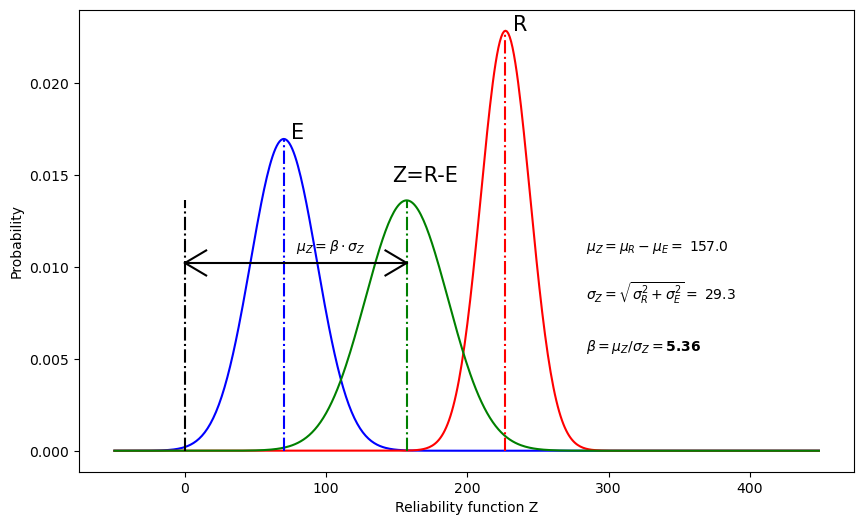

In [165]:
plot_Z(meanE, sdE, meanR, sdR)

In [166]:
import plotly.io as pio
import plotly.graph_objects as go
pio.renderers.default = 'notebook'


## Dynamic graphs of $\beta$ and u.c.

An interactive version and further explanation is visible below. It was written based on these Teachbook pages using Claude AI and the course reader and offers some helpful animations and an option to explore the effect of the different parameters on the structural reliability index and unity check. Also  probability density functions other than the normal distribution can be tested. It is recommended to use the 'Full screen' button the top right of the tool to see all graphs change together in one screen without scrolling:
   <iframe src="../../_static/partial-factors.html" width="100%" height="1250" style="border:0" allow="fullscreen" title="Partial Factors Explorer"></iframe>